# Preprocessament per classificació (C vs I)

Aquest notebook prepara datasets de característiques per a pipelines diferents de classificació.

Sortides:
- NPZ amb `X`, `y`, `y_detail`, `subj_list` i metadades
- CSV amb resum per subjecte

Nom del fitxer de sortida (automàtic):
- Base: `task_canals_finestra_stft`
- Opcional: `_pca` o `_ica` només si s'aplica reducció de dimensionalitat
- Opcional: `_us` només si s'activa undersampling

Exemples:
- `c_vs_i_fcz-oz_1000-1500ms_stft_ica_us.npz`
- `c_vs_i_all_channels_0-1500ms_stft.npz`

Això permet guardar múltiples preprocessaments sense sobreescriure fitxers.

In [1]:
import gc
import importlib.util
import os
import subprocess
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import mne
import numpy as np
import pandas as pd
from scipy.signal import stft
from scipy.stats import chi2
from sklearn.decomposition import FastICA, PCA
from sklearn.preprocessing import StandardScaler

try:
    from google.colab import drive

    IN_COLAB = True
except ImportError:
    drive = None
    IN_COLAB = False

if IN_COLAB:
    required_packages = ["mne", "imbalanced-learn", "xgboost", "lightgbm"]
    for pkg in required_packages:
        if importlib.util.find_spec(pkg.replace("-", "_")) is None:
            subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])
    drive.mount("/content/drive", force_remount=False)

warnings.filterwarnings(
    "ignore",
    category=RuntimeWarning,
    module="mne",
    message=".*does not conform to MNE naming conventions.*",
)
warnings.filterwarnings(
    "ignore",
    category=RuntimeWarning,
    module="mne",
    message=".*events passed to the Epochs constructor are not chronologically ordered.*",
)
mne.set_log_level("WARNING")

print("Imports i configuració de preprocessament carregats.")

Imports i configuració de preprocessament carregats.


In [2]:
# Configuració editable del pipeline de preprocessament
TASK_TAG = "c_vs_i"
REDUCCIO_DE_DIMENSIONALITAT = "ICA"  # opcions: "PCA", "ICA" o None
ELIMINAR_OUTLIERS = True
TARGET_CHANNELS = {"theta": "FCz", "alpha": "Oz"}  # o "all_channels"
TARGET_WINDOW = (1.0, 1.5)
UNDERSAMPLING_PER_INDIVIDU = True

# Recomanació d'ús:
# - 02_classificació_simple: TARGET_CHANNELS={"theta":"FCz","alpha":"Oz"}, TARGET_WINDOW=(1.0,1.5), REDUCCIO="ICA" o "PCA"

print("Configuració editable del preprocessament carregada.")

Configuració editable del preprocessament carregada.


In [3]:
if IN_COLAB:
    DRIVE_ROOT = Path("/content/drive/MyDrive")
    PROJECT_DIR = DRIVE_ROOT / "TFG_Nils_2026"
else:
    DRIVE_ROOT = Path(r"H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU")
    PROJECT_DIR = DRIVE_ROOT / "TFG_Nils_2026"

BASE_DIR = PROJECT_DIR
DATA_DIR = PROJECT_DIR / "02_Data" / "01_Preprocessed_epochs"
META_DIR = PROJECT_DIR / "02_Data" / "02_meta"
ANALYSIS_ROOT = PROJECT_DIR / "04_Anàlisi"
ANALYSIS_DIR = ANALYSIS_ROOT / "00_preprocessament"
FIGURES_DIR = ANALYSIS_DIR / "figures"

for folder in (DATA_DIR, META_DIR, ANALYSIS_ROOT, ANALYSIS_DIR, FIGURES_DIR):
    folder.mkdir(parents=True, exist_ok=True)

DATA_FILES = sorted(DATA_DIR.glob("*.fif"))

COND_EVENTS = {
    "Congruent": ["event_1", "event_2"],
    "Incongruent_Pur": ["event_3", "event_4", "event_5", "event_6"],
    "Incongruent_Mixt": ["event_7", "event_8"],
    "Incongruent": ["event_3", "event_4", "event_5", "event_6", "event_7", "event_8"],
    "Errors": ["event_9", "event_10", "event_11", "event_12"],
}

EVENT_TO_LABEL = {
    1: "CRP",
    2: "CGP",
    3: "IPR",
    4: "IPR",
    5: "IPG",
    6: "IPG",
    7: "IM",
    8: "IM",
    9: "CRG",
    10: "CGG",
    11: "CRM",
    12: "CGM",
}

LABELS = {
    "Congruent": "Congruent (C)",
    "Incongruent_Pur": "Incongruent Pur (IP)",
    "Incongruent_Mixt": "Incongruent Mixt (IM)",
    "Incongruent": "Incongruent (I)",
    "Errors": "Errors",
}
COLORS = {
    "Congruent": "steelblue",
    "Incongruent_Pur": "darkorange",
    "Incongruent_Mixt": "forestgreen",
    "Incongruent": "slategray",
    "Errors": "firebrick",
}

TRIAL_START = -0.74
TRIAL_END = 1.5
FULL_TRIAL = (TRIAL_START, TRIAL_END)
BASELINE = (-0.74, -0.24)
RAMP_UP = (-0.24, 0.0)
STIM_ONSET = (0.0, 1.5)
STIM_OFFSET = (1.5, 2.0)
ERP_WINDOW = (0.0, 0.8)

FINESTRA_1 = (0.0, 0.5)
FINESTRA_2 = (0.5, 1.0)
FINESTRA_3 = (1.0, 1.5)

FREQS_THETA = np.arange(5, 8)
FREQS_ALPHA = np.arange(8, 13)
FREQS_WIDE = np.arange(2, 21)

ROI_FRONTAL = ["Fz", "FCz", "Cz"]
ROI_PO = ["P7", "P8", "PO7", "PO3", "POz", "PO4", "PO8", "O1", "Oz", "O2"]

EYE_LEFT_CODES = [3, 6]
EYE_RIGHT_CODES = [4, 5]
COLOR_RED_CODES = [1, 3, 4, 10]
COLOR_GREEN_CODES = [2, 5, 6, 9]
ERROR_CODES = [9, 10, 11, 12]

STFT_WINDOW_SEC = 0.5
STFT_STEP_SEC = 0.02

N_BINS = 10
RANDOM_STATE = 42
ICA_MAX_COMPONENTS = 20

print(f"Entorn: {'Colab' if IN_COLAB else 'Local'}")
print(f"Projecte: {PROJECT_DIR}")
print(f"Directori de dades: {DATA_DIR}")
print(f"Directori de metadades: {META_DIR}")
print(f"Resultats preprocessament: {ANALYSIS_DIR}")
print(f"Fitxers .fif trobats: {len(DATA_FILES)}")

Entorn: Local
Projecte: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026
Directori de dades: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\02_Data\01_Preprocessed_epochs
Directori de metadades: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\02_Data\02_meta
Resultats preprocessament: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\00_preprocessament
Fitxers .fif trobats: 47


In [4]:
def extract_subject_features(fif_path):
    ep = mne.read_epochs(fif_path, preload=True, verbose=False)
    for ch in ep.info["chs"]:
        ch["unit"] = mne.io.constants.FIFF.FIFF_UNIT_V
    ep.set_channel_types({ch: "eeg" for ch in ep.ch_names}, on_unit_change="ignore")

    required_channels = [TARGET_CHANNELS["theta"], TARGET_CHANNELS["alpha"]]
    missing = [ch for ch in required_channels if ch not in ep.ch_names]
    if missing:
        return None, f"{fif_path.name}: falten canals {missing}"

    ep = ep.copy().pick(required_channels).crop(tmin=TARGET_WINDOW[0], tmax=TARGET_WINDOW[1])

    c_names = [n for n in COND_EVENTS["Congruent"] if n in ep.event_id]
    pur_names = [n for n in COND_EVENTS["Incongruent_Pur"] if n in ep.event_id]
    mixt_names = [n for n in COND_EVENTS["Incongruent_Mixt"] if n in ep.event_id]
    i_names = [n for n in COND_EVENTS["Incongruent"] if n in ep.event_id]

    if not c_names or not i_names:
        return None, f"{fif_path.name}: sense trials C o I"

    selected_names = c_names + i_names
    ep_bin = ep[selected_names]

    c_codes = [ep.event_id[n] for n in c_names]
    pur_codes = [ep.event_id[n] for n in pur_names]
    mixt_codes = [ep.event_id[n] for n in mixt_names]

    events = ep_bin.events[:, 2]
    y_detail = np.full(events.shape[0], "Incongruent", dtype=object)
    y_detail[np.isin(events, c_codes)] = "Congruent"
    y_detail[np.isin(events, pur_codes)] = "Incongruent_Pur"
    y_detail[np.isin(events, mixt_codes)] = "Incongruent_Mixt"
    y = np.where(y_detail == "Congruent", 0, 1)

    x_data = ep_bin.get_data().astype(np.float32, copy=False)
    sfreq = ep_bin.info["sfreq"]
    nperseg = int(round(STFT_WINDOW_SEC * sfreq))
    hop = int(round(STFT_STEP_SEC * sfreq))
    noverlap = max(0, nperseg - hop)
    nfft = max(nperseg, int(round(sfreq)))

    f, t, z = stft(
        x_data,
        fs=sfreq,
        window="hann",
        nperseg=nperseg,
        noverlap=noverlap,
        nfft=nfft,
        boundary="zeros",
        padded=True,
        axis=-1,
    )
    power = np.abs(z) ** 2

    theta_idx = np.array([np.argmin(np.abs(f - fr)) for fr in FREQS_THETA])
    alpha_idx = np.array([np.argmin(np.abs(f - fr)) for fr in FREQS_ALPHA])

    theta_power = power[:, 0:1, theta_idx, :]
    alpha_power = power[:, 1:2, alpha_idx, :]

    X = np.concatenate(
        [theta_power.reshape(theta_power.shape[0], -1), alpha_power.reshape(alpha_power.shape[0], -1)],
        axis=1,
    )

    subject_summary = {
        "subject": fif_path.stem,
        "n_trials": int(len(y)),
        "n_c": int(np.sum(y == 0)),
        "n_i": int(np.sum(y == 1)),
        "n_ip": int(np.sum(y_detail == "Incongruent_Pur")),
        "n_im": int(np.sum(y_detail == "Incongruent_Mixt")),
        "n_features": int(X.shape[1]),
    }

    out = {
        "X": X,
        "y": y,
        "y_detail": y_detail,
        "subject": fif_path.stem,
        "summary": subject_summary,
    }
    return out, None

In [5]:
X_blocks, y_blocks, y_detail_blocks, subj_blocks = [], [], [], []
subject_rows = []
skipped = []

for fif_path in DATA_FILES:
    out, err = extract_subject_features(fif_path)
    if err is not None:
        skipped.append(err)
        continue

    X_blocks.append(out["X"])
    y_blocks.append(out["y"])
    y_detail_blocks.append(out["y_detail"])
    subj_blocks.extend([out["subject"]] * len(out["y"]))
    subject_rows.append(out["summary"])

if not X_blocks:
    raise RuntimeError("No s'han pogut extreure característiques de cap subjecte.")

X = np.vstack(X_blocks)
y = np.concatenate(y_blocks)
y_detail = np.concatenate(y_detail_blocks).astype(object)
subj_list = np.array(subj_blocks, dtype=object)

ICA_MAX_COMPONENTS = 20
ICA_COMPONENTS = min(ICA_MAX_COMPONENTS, X.shape[1])

reduction_mode = REDUCCIO_DE_DIMENSIONALITAT
if reduction_mode == "PCA":
    reducer = PCA(n_components=min(ICA_COMPONENTS, X.shape[1]), random_state=42)
    X_reduced = reducer.fit_transform(StandardScaler().fit_transform(X))
elif reduction_mode == "ICA":
    reducer = FastICA(
        n_components=min(ICA_COMPONENTS, X.shape[1]),
        random_state=42,
        whiten="unit-variance",
        max_iter=1000,
        tol=0.0005,
    )
    X_reduced = reducer.fit_transform(StandardScaler().fit_transform(X))
else:
    X_reduced = X

X_scaled = StandardScaler().fit_transform(X_reduced)
ica_m = FastICA(
    n_components=min(ICA_COMPONENTS, X_scaled.shape[1]),
    random_state=42,
    whiten="unit-variance",
    max_iter=1000,
    tol=0.0005,
)
X_ica = ica_m.fit_transform(X_scaled)
md_mean = np.mean(X_ica, axis=0)
md_cov = np.cov(X_ica, rowvar=False)
md_inv_cov = np.linalg.pinv(md_cov)
md_diff = X_ica - md_mean
md2 = np.einsum("ij,jk,ik->i", md_diff, md_inv_cov, md_diff)
md_values = np.sqrt(np.clip(md2, 0, None))
md_threshold = float(np.sqrt(chi2.ppf(0.999, df=X_ica.shape[1])))
is_outlier = md_values > md_threshold

if ELIMINAR_OUTLIERS:
    keep_mask = ~is_outlier
    X = X[keep_mask]
    X_reduced = X_reduced[keep_mask]
    y = y[keep_mask]
    y_detail = y_detail[keep_mask]
    subj_list = subj_list[keep_mask]
    md_values = md_values[keep_mask]
    is_outlier = is_outlier[keep_mask]

if UNDERSAMPLING_PER_INDIVIDU:
    rng = np.random.default_rng(42)
    keep_indices = []
    for subj in np.unique(subj_list):
        idx_subj = np.where(subj_list == subj)[0]
        y_subj = y[idx_subj]
        idx_c = idx_subj[y_subj == 0]
        idx_i = idx_subj[y_subj == 1]
        n_min = min(len(idx_c), len(idx_i))
        if n_min == 0:
            skipped.append(f"{subj}: sense mostres a una classe després del filtratge")
            continue
        pick_c = rng.choice(idx_c, size=n_min, replace=False)
        pick_i = rng.choice(idx_i, size=n_min, replace=False)
        keep_indices.extend(np.concatenate([pick_c, pick_i]).tolist())

    if not keep_indices:
        raise RuntimeError("UNDERSAMPLING_PER_INDIVIDU=True però no hi ha dades vàlides després del balanç.")

    keep_indices = np.array(keep_indices, dtype=int)
    rng.shuffle(keep_indices)

    X = X[keep_indices]
    X_reduced = X_reduced[keep_indices]
    y = y[keep_indices]
    y_detail = y_detail[keep_indices]
    subj_list = subj_list[keep_indices]
    md_values = md_values[keep_indices]
    is_outlier = is_outlier[keep_indices]

subject_rows = [
    {
        "subject": subj,
        "n_trials": int(np.sum(subj_list == subj)),
        "n_c": int(np.sum((subj_list == subj) & (y == 0))),
        "n_i": int(np.sum((subj_list == subj) & (y == 1))),
        "n_ip": int(np.sum((subj_list == subj) & (y_detail == "Incongruent_Pur"))),
        "n_im": int(np.sum((subj_list == subj) & (y_detail == "Incongruent_Mixt"))),
        "n_features": int(X.shape[1]),
    }
    for subj in np.unique(subj_list)
]

df_subject_summary = pd.DataFrame(subject_rows).sort_values("subject").reset_index(drop=True)

print(f"Mostres totals: {len(y)}")
print(f"C: {(y == 0).sum()} | I: {(y == 1).sum()}")
print(f"Subjectes inclosos: {len(np.unique(subj_list))}")
print(f"Dimensió features: {X.shape}")
print(f"Mode reducció dimensional: {REDUCCIO_DE_DIMENSIONALITAT}")
print(f"ICA_COMPONENTS recomanat (màxim): {ICA_COMPONENTS}")
if ELIMINAR_OUTLIERS:
    print(f"Atípics detectats (ICA+Mahalanobis): {is_outlier.sum()} de {len(X)} ({is_outlier.mean() * 100:.2f}%)")
print(f"Undersampling per individu: {UNDERSAMPLING_PER_INDIVIDU}")
if skipped:
    print("Notes/subjectes omesos:")
    for msg in skipped:
        print(f"  - {msg}")

Mostres totals: 15208
C: 7604 | I: 7604
Subjectes inclosos: 47
Dimensió features: (15208, 216)
Mode reducció dimensional: ICA
ICA_COMPONENTS recomanat (màxim): 20
Atípics detectats (ICA+Mahalanobis): 0 de 15208 (0.00%)
Undersampling per individu: True


In [6]:
# Fitxer .npz va a DATA_DIR/processed, però subject_summary.csv va a META_DIR
processed_dir = DATA_DIR / "processed"
processed_dir.mkdir(parents=True, exist_ok=True)
meta_dir = META_DIR
meta_dir.mkdir(parents=True, exist_ok=True)

if isinstance(TARGET_CHANNELS, dict):
    channels_for_tag = sorted(set(TARGET_CHANNELS.values()))
elif isinstance(TARGET_CHANNELS, (list, tuple, np.ndarray)):
    channels_for_tag = list(TARGET_CHANNELS)
elif isinstance(TARGET_CHANNELS, str) and TARGET_CHANNELS.lower() == "all_channels":
    channels_for_tag = ["all_channels"]
else:
    channels_for_tag = [str(TARGET_CHANNELS)]

if len(channels_for_tag) == 1 and channels_for_tag[0].lower() == "all_channels":
    channels_tag = "all_channels"
elif len(channels_for_tag) <= 4:
    channels_tag = "-".join([ch.lower() for ch in channels_for_tag])
else:
    channels_tag = f"{len(channels_for_tag)}ch"

window_tag = f"{int(TARGET_WINDOW[0]*1000)}-{int(TARGET_WINDOW[1]*1000)}ms"
name_parts = [TASK_TAG, channels_tag, window_tag, "stft"]

if REDUCCIO_DE_DIMENSIONALITAT in {"PCA", "ICA"}:
    name_parts.append(REDUCCIO_DE_DIMENSIONALITAT.lower())
if UNDERSAMPLING_PER_INDIVIDU:
    name_parts.append("us")

pipeline_name = "_".join(name_parts)

dataset_path = processed_dir / f"{pipeline_name}.npz"
summary_path = meta_dir / f"{pipeline_name}_subject_summary.csv"

np.savez_compressed(
    dataset_path,
    X=X.astype(np.float32),
    y=y.astype(np.int8),
    y_detail=y_detail.astype(str),
    subj_list=subj_list.astype(str),
    freqs_theta=FREQS_THETA.astype(np.int16),
    freqs_alpha=FREQS_ALPHA.astype(np.int16),
    target_window=np.array(TARGET_WINDOW, dtype=np.float32),
    stft_window_sec=np.float32(STFT_WINDOW_SEC),
    stft_step_sec=np.float32(STFT_STEP_SEC),
    ica_components=np.int16(ICA_COMPONENTS),
    reduction_mode=np.array(REDUCCIO_DE_DIMENSIONALITAT, dtype=object),
    eliminate_outliers=np.bool_(ELIMINAR_OUTLIERS),
    undersampling_per_individu=np.bool_(UNDERSAMPLING_PER_INDIVIDU),
    feature_channels=np.array(channels_for_tag, dtype=object),
    task_tag=np.array(TASK_TAG, dtype=object),
    pipeline_name=np.array(pipeline_name, dtype=object),
)

df_subject_summary.to_csv(summary_path, index=False)

print(f"Pipeline: {pipeline_name}")
print(f"Dataset desat a: {dataset_path}")
print(f"Resum per subjecte desat a: {summary_path}")

Pipeline: c_vs_i_fcz-oz_1000-1500ms_stft_ica_us
Dataset desat a: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\02_Data\01_Preprocessed_epochs\processed\c_vs_i_fcz-oz_1000-1500ms_stft_ica_us.npz
Resum per subjecte desat a: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\02_Data\02_meta\c_vs_i_fcz-oz_1000-1500ms_stft_ica_us_subject_summary.csv


,subject,n_trials,n_c,n_i,n_ip,n_im,n_features
0,P002,226,113,113,66,47,216
1,P003,144,72,72,38,34,216
2,P004,428,214,214,39,175,216
3,P005,306,153,153,61,92,216
4,P008,174,87,87,33,54,216
5,P009,346,173,173,56,117,216
6,P010,486,243,243,101,142,216
7,P011,232,116,116,65,51,216
8,P013,448,224,224,102,122,216
9,P014,228,114,114,27,87,216


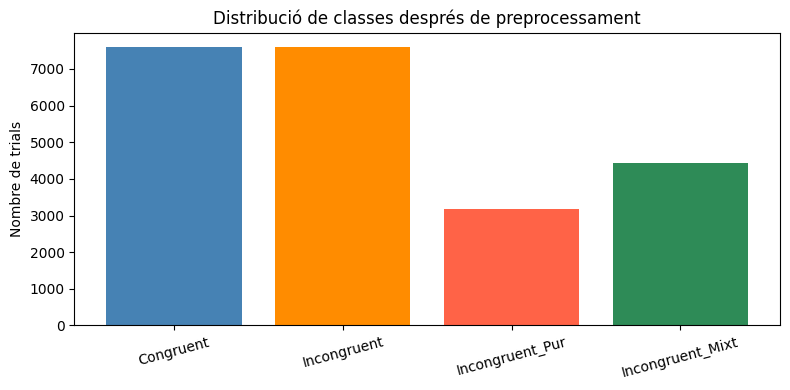

In [7]:
display(df_subject_summary)

class_counts = {
    "Congruent": int(np.sum(y_detail == "Congruent")),
    "Incongruent": int(np.sum(y_detail != "Congruent")),
    "Incongruent_Pur": int(np.sum(y_detail == "Incongruent_Pur")),
    "Incongruent_Mixt": int(np.sum(y_detail == "Incongruent_Mixt")),
}

plt.figure(figsize=(8, 4))
plt.bar(class_counts.keys(), class_counts.values(), color=["steelblue", "darkorange", "tomato", "seagreen"])
plt.xticks(rotation=15)
plt.ylabel("Nombre de trials")
plt.title("Distribució de classes després de preprocessament")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "distribucio_classes_despres_preprocessament.png", dpi=300, bbox_inches="tight")
plt.show()